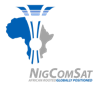 &nbsp;&nbsp; 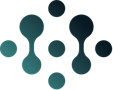

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/main/Jasons-Restructure/week-6/day-2-remaining-useful-life-and-quiz-4/2-exercise/W6D2-exercise.ipynb)

# ⛽ Week 6 · Day 2: When Will It Break? Remaining Useful Life

**Today:** you make the code book's remaining-useful-life calls, find (and fix) the bug that sends the propellant back to day 0, then check the battery call against what really happened, from four different starting points.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**

**Rule book:** keep `W6D2-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up
Run it once every time you open the notebook (and after every restart). Wait for `✅ Ready!`.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

def load_labels(name="telemetry_anomaly_labels", week=None):
    """Read an answer-key (labels) file. The original telemetry_anomaly_labels.csv has a stray comma
    inside one description, which makes pd.read_csv crash, so the last column is read as free text."""
    lines = Path(data_path(name, week)).read_text(encoding="utf-8").splitlines()
    cols = lines[0].split(",")
    rows = [ln.split(",", len(cols) - 1) for ln in lines[1:] if ln.strip()]
    df = pd.DataFrame(rows, columns=cols)
    for c in ("start", "end"):
        if c in df:
            df[c] = pd.to_datetime(df[c], format="mixed")
    return df

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def _near(x, want, tol):
    return abs(float(x) - want) <= tol

def _day(x):
    return None if x is None or pd.isna(x) else str(pd.Timestamp(x).date())

def _c_a1(x):
    return _near(x, -4.591703118536416, 0.01), \
        f"{float(x):.2f}% a year: the battery loses about four and a half points of capacity every year. 📉", \
        "A slope per day times the number of days in a year: 365."

def _c_a2(x):
    got = {r["asset"]: _day(r["predicted_date"]) for _, r in x.iterrows()}
    return got == {'BATT-A': '2025-05-01', 'TWTA-A': '2033-05-05', 'PROP-A': None}, \
        "Battery 1 May 2025, amplifier 5 May 2033, and the propellant says None: no crossing inside the search window. Next task: what did the original say? 🤔", \
        "The limit value lives in the column called \"threshold\". Type it as text, with quotes."

def _c_a3(x):
    return bool(x[0]) is False and int(x[1]) == 0, \
        "Never crossed, so every value is False, and np.argmax of all-False is 0: day 0 = 1 Jan 2021. A confident wrong date with no error. 🐞", \
        "Look at the print: how many days in the window are below 5 kg? If none, did it cross?"

def _c_a4(x):
    return _day(x) == '2035-12-06', \
        "6 Dec 2035: the line does reach 5 kg, just after the 4,000-day search stopped (13 Dec 2034). 🔭", \
        "Solve the straight line for the threshold: (5.0 - intercept) / slope"

def _c_a5(x):
    return _near(x, 10.076647355027344, 0.01), \
        f"{float(x):.1f} years, about January 2036. The danfo-driver sum agrees with the line (6 Dec 2035). ⛽", \
        "The reserve in degradation_thresholds.csv is 5 kg: RESERVE_KG = 5.0"

def _c_b1(x):
    got = tuple(_day(x[k]) for k in ("first_dip", "30_day_mean", "last_good_day"))
    return got == ('2025-05-14', '2025-06-20', '2025-07-24'), \
        "First dip 14 May 2025, 30-day mean 20 Jun 2025, last good day 24 Jul 2025: the crossing is a window, not a day. 🪟", \
        "The battery's floor, in %: FLOOR = 80.0"

def _c_b2(x):
    return tuple(int(v) for v in x) == (13, 50), \
        "13 days early against the first dip (the code book's answer), 50 against the 30-day mean. Same forecast, two scores: define 'crossed' first. ⚖️", \
        "Use the key exactly as printed in cross: \"30_day_mean\""

def _c_b3(x):
    return [int(v) for v in x["days_vs_first_dip"]] == [-74, -37, -13, 4] and [int(v) for v in x["warning_days"]] == [1229, 864, 499, 134], \
        "More data, closer call, less warning: from 1,229 days of warning down to 134. That trade-off is the whole game. ⏳", \
        "A list of the four amounts of data: YEARS = [1, 2, 3, 4]"

def _c_b4(x):
    return "slow" in str(x).lower(), \
        "It slows. A line fitted on the early, faster years overstates the later fade, so the calls land early: the safe side. 🐢", \
        "Read the slopes: is the yearly loss getting bigger or smaller? Type \"slows\" or \"speeds up\"."

def _c_c1(x):
    v = float(x)
    v = v / 100 if v > 1 else v
    return _near(v, 0.43369663941871084, 0.002), \
        "43.4% of the fade happens on eclipse days, which are only 24.7% of the calendar: 2.3x faster. The battery ages when it works. 🌘", \
        "Eclipse days have eclipse_flag equal to 1: ECLIPSE = 1"

def _c_c2(x):
    return _near(x, 7.230663928815879, 0.02), \
        "7.2 years past the end of the data, and that's the BEST call (5 years of data). Give a range and re-estimate every year. 🎯", \
        "The last day of data is degr.index[-1]: LAST = -1"

def _c_c3(x):
    return str(x).strip().upper() == "B", \
        "B: a planning figure with a range, how far it reaches, and when you'll check again. That is how a professional reports it. 🧑🏾‍🔧", \
        "A gives one exact day; C refuses to say anything. Which one helps the planner AND tells the truth?"

def _c_bonus(x):
    return _day(x) == '2025-06-14', \
        "14 Jun 2025: a curve that bends with the slowing fade lands INSIDE the real window. Careful though: curves can go wild over long reaches like the amplifier's. 🌶️", \
        "A curve with one bend is degree 2: DEGREE = 2"

CHECKS = {"A1": _c_a1, "A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "A5": _c_a5, "B1": _c_b1, "B2": _c_b2, "B3": _c_b3,
          "B4": _c_b4, "C1": _c_c1, "C2": _c_c2, "C3": _c_c3, "BONUS": _c_bonus}
HINTS = {"A2": "COLUMN is the NAME of a column of limits, as text.", "B3": "YEARS is a list of numbers, like [1, 2, 3, 4]."}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


### ▶️ The data and the limits
Five years of daily readings from one **synthetic** GEO satellite (the same made-up platform as Week 5), and a small table of operational limits. The limits are **known up front**: we forecast *when* they are reached, not what they are.

In [ ]:
degr = pd.read_csv(data_path("degradation_assets_daily"), parse_dates=["date"], index_col="date").asfreq("D")
limits = pd.read_csv(data_path("degradation_thresholds"))
print("days:", len(degr), "·", degr.index[0].date(), "to", degr.index[-1].date(), "· gaps:", int(degr.isna().sum().sum()))
display(limits[["asset", "channel", "unit", "threshold", "direction"]])

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (_, row) in zip(axes, limits.iterrows()):
    ax.plot(degr.index, degr[row["channel"]], lw=0.8)
    ax.axhline(row["threshold"], color="#C0504D", ls="--", label=f"limit: {row['threshold']} {row['unit']}")
    ax.set_title(f"{row['asset']}: {row['channel']}")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### ▶️ Your tools for today
Three small functions (read them once, then run):
- `fit_trend(series)` fits the best straight line through day number vs value. It returns the line and its two numbers, **slope** and **intercept**.
- `day_of_threshold(series, threshold)` extends that line forward until it crosses the limit, and returns the **day number**. If it never crosses inside the search window, it returns **`None`** (the original code book had a bug here: you'll find it in A3).
- `crossing_dates(series, threshold)` answers *"when did it actually cross?"* three ways (Part B).

In [ ]:
def fit_trend(series, degree=1):
    """Fit day-number vs value. Returns the fitted line (callable) and its numbers (slope, intercept)."""
    x = np.arange(len(series))
    coef = np.polyfit(x, series.values, degree)
    return np.poly1d(coef), coef

def day_of_threshold(series, threshold, direction="falls_below", degree=1, extra_days=4000):
    """Extend the trend forward until it crosses the threshold. Returns (day number, line).
    FIXED: returns None when it does not cross inside the search window (the original said day 0)."""
    model, coef = fit_trend(series, degree)
    y_future = model(np.arange(len(series) + extra_days))
    crossed = y_future < threshold if direction == "falls_below" else y_future > threshold
    if not crossed.any():
        return None, model
    return int(np.argmax(crossed)), model

def crossing_dates(series, threshold, window=30):
    """Three honest answers to "when did it cross?" for a falling series."""
    below = series < threshold
    smooth = series.rolling(window).mean()
    return {"first_dip": series.index[below.values.argmax()],
            f"{window}_day_mean": smooth.index[(smooth < threshold).values.argmax()],
            "last_good_day": series[~below].index[-1]}

print("✅ fit_trend(), day_of_threshold() and crossing_dates() are ready")

---
# Part A: Draw the line (15 min) 📏

📖 The honest rule from the code book: make the call using **only the first three years**, as if it were the morning of 1 January 2024. The two later years are kept aside to check the call in Part B.

### A1 ✍️ How fast is the battery fading?
`fit_trend` gives the slope **per day**. Turn it into a slope **per year**: how many days are in a year?

In [ ]:
TRAIN_DAYS = 365 * 3
known = degr.iloc[:TRAIN_DAYS]
model, (slope_per_day, intercept) = fit_trend(known["battery_capacity_pct"])
print(f"slope: {slope_per_day:.5f} % per day · intercept: {intercept:.2f} %")

DAYS_PER_YEAR = ___

assert DAYS_PER_YEAR is not None, "✍️ Fill in DAYS_PER_YEAR first."
slope_per_year = slope_per_day * DAYS_PER_YEAR
print(f"slope: {slope_per_year:.2f} % per year")
check("A1", slope_per_year)

### A2 ✍️ The three calls
The loop makes the call for every row of `limits`. `day_of_threshold` needs each part's limit value: which **column** of `limits` holds it? Type the column name as text, like `"unit"`.

In [ ]:
COLUMN = ___

assert COLUMN is not None, "✍️ Fill in COLUMN first."
assert isinstance(COLUMN, str), "✍️ COLUMN is the NAME of a column, as text in quotes."
rows = []
for _, row in limits.iterrows():
    day, _ = day_of_threshold(known[row["channel"]], row[COLUMN], row["direction"])
    rows.append({"asset": row["asset"], "channel": row["channel"], "limit": row[COLUMN],
                 "predicted_day": day,
                 "predicted_date": None if day is None else (degr.index[0] + pd.Timedelta(days=day)).date()})
calls = pd.DataFrame(rows)
display(calls)
check("A2", calls)

### A3 ✍️ What did the original code book print for the propellant?
The original searched **4,000 days** past the data and took `np.argmax` of "is the line below the limit?". It printed **1 Jan 2021** for the propellant: the first day of the data. ▶️ Run the cell and read the two prints.
Then ✍️: did the line cross 5 kg inside the search window, `True` or `False`?

In [ ]:
model_p, coef_p = fit_trend(known["propellant_kg"])
y_future = model_p(np.arange(len(known) + 4000))   # the 4,000-day search
crossed = y_future < 5.0
print("days in the search window below 5 kg:", int(crossed.sum()))
original_day = np.argmax(crossed)
print("np.argmax says day", original_day, "→", (degr.index[0] + pd.Timedelta(days=int(original_day))).date())

crossed_in_window = ___

check("A3", (crossed_in_window, original_day))

> 📖 **The bug:** `np.argmax` returns the position of the *first* `True`. When there is no `True` at all, every value ties and it returns **0**. No error, no warning: a confident wrong date. Our `day_of_threshold` checks `crossed.any()` first and returns `None`, so the honest answer is *"no crossing inside the search window"*.

### A4 ✍️ Look further: solve the line
A straight line is `value = slope × day + intercept`. Set the value to the 5 kg reserve and solve for the day: `(5.0 - intercept) / slope`.

In [ ]:
slope, intercept = coef_p
print(f"propellant line: {slope * 365:.2f} kg per year")

crossing_day = ___

assert crossing_day is not None, "✍️ Fill in crossing_day first."
prop_line_date = degr.index[0] + pd.Timedelta(days=int(crossing_day))
print("the line reaches 5 kg on", prop_line_date.date())
check("A4", prop_line_date)

### A5 ✍️ The danfo driver's fuel-gauge sum
No model at all: what's left **above the reserve**, divided by what is burned in a year. How many kg must stay in the tank for the de-orbit burn?

In [ ]:
prop = degr["propellant_kg"]
kg_per_year = (prop.iloc[0] - prop.iloc[-1]) / (len(prop) - 1) * 365
print(f"left on {prop.index[-1].date()}: {prop.iloc[-1]:.2f} kg · burned: {kg_per_year:.2f} kg per year")

RESERVE_KG = ___

assert RESERVE_KG is not None, "✍️ Fill in RESERVE_KG first."
years_left = (prop.iloc[-1] - RESERVE_KG) / kg_per_year
empty_date = prop.index[-1] + pd.Timedelta(days=years_left * 365.25)
print(f"years left: {years_left:.1f} → about {empty_date:%B %Y}")
check("A5", years_left)

---
# Part B: Was the battery call right? (15 min) 🔍

### B1 ✍️ When did it actually cross?
Daily readings are noisy, so "crossed" has more than one honest meaning. `crossing_dates` gives three: the **first day below**, the first day the **30-day mean** is below, and the **last day still at or above**. What is the battery's floor, in %?

In [ ]:
bat = degr["battery_capacity_pct"]

FLOOR = ___

assert FLOOR is not None, "✍️ Fill in FLOOR first."
cross = crossing_dates(bat, FLOOR, window=30)
for name, day in cross.items():
    print(f"{name:14s} {day.date()}")
window = bat.loc[cross["first_dip"]:cross["last_good_day"]]
print(f"\nin between: {int((window < FLOOR).sum())} of {len(window)} days are below {FLOOR}%")
check("B1", cross)

### B2 ✍️ Score the 3-year call
`CALL` is the battery date from your A2 table. The first score is done for you. ✍️ Score it again against the 30-day mean: type that key of `cross`, exactly as printed above.

In [ ]:
assert "calls" in globals(), "✍️ Finish A2 first, then run this cell."
CALL = pd.Timestamp(calls.loc[calls["asset"] == "BATT-A", "predicted_date"].iloc[0])
print("the 3-year call:", CALL.date())

KEY = ___

assert KEY is not None, "✍️ Fill in KEY first."
early_vs_first_dip = (cross["first_dip"] - CALL).days
early_vs_30_day = (cross[KEY] - CALL).days
print(f"days early vs the first dip: {early_vs_first_dip} · vs the 30-day mean: {early_vs_30_day}")
check("B2", (early_vs_first_dip, early_vs_30_day))

### B3 ✍️ Backtest the method: four starting points
One good call could be luck (Week 6 Day 1). Make the call as if you were standing at the end of year 1, 2, 3 and 4, with only the data you had then. ✍️ `YEARS` is the list of those four amounts of data.
Negative = the call came **early**. `warning_days` = how long you had to act before the first dip.

In [ ]:
YEARS = ___

assert YEARS is not None, "✍️ Fill in YEARS first."
assert "cross" in globals(), "✍️ Finish B1 first, then run this cell."
first_dip, mean30 = cross["first_dip"], cross["30_day_mean"]
rows = []
for years in YEARS:
    n_days = 365 * years
    day, _ = day_of_threshold(bat.iloc[:n_days], 80.0)
    call = degr.index[0] + pd.Timedelta(days=day)
    rows.append({"years_of_data": years, "call_made_on": degr.index[n_days].date(), "predicted_crossing": call.date(),
                 "days_vs_first_dip": (call - first_dip).days, "days_vs_30_day_mean": (call - mean30).days,
                 "warning_days": (first_dip - degr.index[n_days]).days})
repeat = pd.DataFrame(rows)
display(repeat)
check("B3", repeat)

### B4 ✍️ Why do the calls land early?
▶️ The cell fits a line through each calendar year separately. ✍️ Is the yearly fade getting bigger or smaller? Type `"slows"` or `"speeds up"`.

In [ ]:
slopes = {year: fit_trend(bat[str(year)])[1][0] * 365 for year in range(2021, 2026)}
for year, s in slopes.items():
    print(f"{year}: {s:.2f} % per year")

fade_is = ___

check("B4", fade_is)

---
# Part C: Look closer, reach further (12 min) 🎯

### C1 ✍️ Does the battery age faster in eclipse season?
In the eclipse seasons the battery carries the satellite through the Earth's shadow every night. `daily` is each day's change in capacity (negative = fade). ✍️ Eclipse days have `eclipse_flag` equal to what number?

In [ ]:
daily = bat.diff().dropna()

ECLIPSE = ___

assert ECLIPSE is not None, "✍️ Fill in ECLIPSE first."
in_eclipse = degr["eclipse_flag"].loc[daily.index] == ECLIPSE
share_of_days = in_eclipse.mean()
share_of_fade = daily[in_eclipse].sum() / daily.sum()
print(f"eclipse days: {share_of_days:.1%} of the calendar · {share_of_fade:.1%} of all the fade")
print(f"fade per day, eclipse vs sunlight: {daily[in_eclipse].mean() / daily[~in_eclipse].mean():.1f}x")
check("C1", share_of_fade)

### C2 ✍️ The long reach: the amplifier
The amplifier is nowhere near −2 dB yet, so its call can't be checked. ▶️ The cell makes the call from 1 to 5 years of data. ✍️ How far past the **last day of data** does even the best (5-year) call reach? The last day is `degr.index[LAST]`: what position is the last item of a list?

In [ ]:
LAST = ___

assert LAST is not None, "✍️ Fill in LAST first."
gain = degr["twta_gain_db"]
amp_calls = []
for years in [1, 2, 3, 4, 5]:
    model, (slope, intercept) = fit_trend(gain.iloc[:365 * years])
    amp_calls.append(degr.index[0] + pd.Timedelta(days=int((-2.0 - intercept) / slope)))
for years, t in zip([1, 2, 3, 4, 5], amp_calls):
    print(f"{years} year(s) of data → gain reaches -2 dB on {t.date()}")

reach_years = (amp_calls[-1] - degr.index[LAST]).days / 365.25
print(f"\nthe 5-year call reaches {reach_years:.1f} years past the last day of data")
check("C2", reach_years)

### C3 ✍️ The honest report
Which sentence would you send to the fleet planner about the amplifier? Type `"A"`, `"B"` or `"C"`.
- **A.** "The amplifier gain will fall below −2 dB on 5 May 2033."
- **B.** "Around 2033 (calls made from 1 to 5 years of data span March to November 2033). That is more than 7 years past our data, so we will re-estimate every year."
- **C.** "We can't say anything until it fails."

In [ ]:
honest = ___

check("C3", honest)

---
## 🌶️ Pepper task: bend the line
The fade is slowing, so a straight line calls early. `day_of_threshold` can fit a **curve** instead: `degree=1` is a straight line, a curve with one bend is the next degree up. ✍️ Same three years of data: where does the curve land?

In [ ]:
DEGREE = ___

assert DEGREE is not None, "✍️ Fill in DEGREE first."
day, _ = day_of_threshold(known["battery_capacity_pct"], 80.0, degree=DEGREE)
curve_call = degr.index[0] + pd.Timedelta(days=day)
print("curve call:", curve_call.date(), "· real window:", cross["first_dip"].date(), "to", cross["last_good_day"].date())
check("BONUS", curve_call)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- **Remaining useful life** = fit the trend, extend it until it crosses the known limit. The battery's 3-year line hits 80% on **1 May 2025**.
- **Check the "never" case.** `np.argmax` of all-False is 0, which made the original print 1 Jan 2021. Say "no crossing inside the window", then solve the line: **6 Dec 2035**. The fuel-gauge sum agrees (10.1 years).
- **"Crossed" is a window**, from the first dip (14 May 2025) to the last good day (24 Jul 2025). Define it before you score.
- **Backtest the method** from several starting points: more data gives a closer call but less warning. The straight line errs early because the fade slows.
- **Report a window**, say how far past the data you reach, act before the crossing, and re-estimate regularly.

**Next time:** *Project clinic & demo day*: five minutes to show your unit what you built. 🎤

<sub>Data: synthetic teaching dataset from the original Week 6 code book (`Time-series/week-06`). Safe to use with AI tools; real NIGCOMSAT data is not.</sub>